# Enzymatic diversity scout

Goal: find a diversity term that makes **expressed enzymes carry flux in proportion to how much of them there is**, without hurting the homeostatic objective.

Workflow:
1. Load a timeseries sim (`0_output.npy` + `agent_steps.pkl`).
2. Pull enzyme (catalyst) counts for one snapshot.
3. Rebuild the metabolism FBA problem in CVXPY for that snapshot, with a pluggable diversity term.
4. Check the rebuild against the sim's own solution.
5. Compare candidate diversity terms.

Equations (plain text):
```
pair flux           g_r   = Σ_{j ∈ pair r} v_j          (forward + reverse)
uniform floor       ε_r   = c2m                          (1 molecule per step)
enzyme floor        ε_i   = clip( k_cat_min × Δt × Σ_{e ∈ C_i} [E_e] / n_rxn_involved_per_cat ,
                                  lower = c2m, upper = ε_hi )
                    ε_r   = max over i in pair r of ε_i
floor term          T_div = Σ_{r : ε_r > 0} (1 / ε_r) × max(0, ε_r − g_r)

where [E_e] = count_e × c2m, n_rxn_involved_per_cat = number of reaction pairs catalyst e serves,
C_i = catalysts of FBA reaction i, c2m = counts_to_molar at this step.
```

In [1]:
%matplotlib inline
import sys
import time
from pathlib import Path

import cvxpy as cp
import dill
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr
from IPython.display import display

# Repo root = first parent folder containing pyproject.toml
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ecoli.processes.metabolism_redux_classic import NetworkFlowModel
from reconstruction.ecoli.dataclasses.process.metabolism import REVERSE_TAG

# Any timeseries sim folder with 0_output.npy and agent_steps.pkl
SIM_FOLDER = Path("/Users/heenasaqib/dev/vEcoli/out/phenotypic/basal_new_hom_only_stoich_adj_2500_2026-10-01")
T = 1250  # snapshot timestep index
print("repo:", REPO_ROOT)
print("sim: ", SIM_FOLDER)

repo: /Users/heenasaqib/dev/vEcoli
sim:  /Users/heenasaqib/dev/vEcoli/out/phenotypic/basal_new_hom_only_stoich_adj_2500_2026-10-01


## 1. Load the sim

In [2]:
output = np.load(SIM_FOLDER / "0_output.npy", allow_pickle=True).item()["agents"]["0"]
with open(SIM_FOLDER / "agent_steps.pkl", "rb") as f:
    metabolism = dill.load(f)["ecoli-metabolism-redux-classic"]

fba = output["listeners"]["fba_results"]
enzyme_kinetics = output["listeners"]["enzyme_kinetics"]
n_steps = len(fba["solution_fluxes"])

reaction_names = list(metabolism.reaction_names)
catalyst_ids = list(metabolism.parameters["catalyst_ids"])
sim_weights = dict(metabolism.parameters["objective_weights"])
fraction_kinetic_target = metabolism.parameters["fraction_kinetic_target"]
dt = float(metabolism.timestep)

print(f"{n_steps} steps, {len(reaction_names)} FBA reactions, {len(catalyst_ids)} catalysts")
print("sim objective weights:", sim_weights)

2501 steps, 9456 FBA reactions, 1562 catalysts
sim objective weights: {'secretion': 1e-06, 'efficiency': 1e-06, 'kinetics': 1e-07, 'diversity': 1e-07, 'homeostatic': 1}


## 2. Enzyme counts at the snapshot

In [27]:
c2m = float(enzyme_kinetics["counts_to_molar"][T])
# -1 = no catalyst, catalyst counts for each FBA reaction. sums isozymes
rxn_catalyst_counts = np.asarray(fba["reaction_catalyst_counts"][T], dtype=float)
# aligned with catalyst_ids, individual catalyst count
catalyst_counts = np.asarray(fba["catalyst_counts"][T], dtype=float)

# Forward/reverse pairing: pair key = reaction id without REVERSE_TAG
pair_keys = [r[: -len(REVERSE_TAG)] if r.endswith(REVERSE_TAG) else r for r in reaction_names]
pair_index = {k: i for i, k in enumerate(dict.fromkeys(pair_keys))}

# for each FBA, point to the index of its reaction pair.
# E.g. "1.1.1.127-RXN" has 1 and "1.1.1.127-RXN (Reverse)" has 1
pair_of_rxn = np.array([pair_index[k] for k in pair_keys])
n_pairs = len(pair_index) # number of unique reaction pairs
G = csr_matrix((np.ones(len(reaction_names)), (pair_of_rxn, np.arange(len(reaction_names)))),
               shape=(n_pairs, len(reaction_names)))

# for each catalyst, assign the reactions it serves. fwd/rev is considered the same reaction
pairs_per_catalyst = [set() for _ in catalyst_ids]
for i, enz_idx in enumerate(metabolism.catalyzed_rxn_enzymes_idx): # each reaction's catalysts
    for e in enz_idx:
        pairs_per_catalyst[e].add(pair_of_rxn[i])
n_rxn_involved_per_cat = np.array([max(len(s), 1) for s in pairs_per_catalyst])

# For each FBA reaction, get how much catalyst is available to it
# That "how much" is determined by Σ_e count_e / n_rxn_involved_per_cat
# e.g. if a reaction had two catalyst, each serving 1 and 10 reactions
#     the math would be count_1/1 + count_2/10, so the second catalyst contributes 1/10th of its count to this reaction.
avg_cat_count_per_rxn = np.array([
    sum(catalyst_counts[e] / n_rxn_involved_per_cat[e] for e in enz_idx) if len(enz_idx) else -1.0
    for enz_idx in metabolism.catalyzed_rxn_enzymes_idx
])

status = np.where(rxn_catalyst_counts < 0, "no catalyst",
                  np.where(rxn_catalyst_counts == 0, "absent", "expressed"))

rxn_df = pd.DataFrame({

    "reaction": reaction_names,
    "pair": pair_of_rxn,
    "n_catalysts": [len(x) for x in metabolism.catalyzed_rxn_enzymes_idx],
    "raw_count": rxn_catalyst_counts,
    "avg_cat_count_per_rxn": avg_cat_count_per_rxn,
    "status": status,
    "new_2022": np.isin(reaction_names, metabolism.parameters["fba_new_reaction_ids"]),
})
print(f"t = {T}, counts_to_molar = {c2m:.3e}, {n_pairs} reaction pairs")
rxn_df["status"].value_counts().to_frame("FBA reactions")

t = 1250, counts_to_molar = 1.136e-06, 6795 reaction pairs


,FBA reactions
status,
expressed,8276
no catalyst,1080
absent,100


# Catalysts shared by the most reaction pairs (these dominate raw summed counts)
top = np.argsort(-n_rxn_involved_per_cat)[:10]
pd.DataFrame({"catalyst": [catalyst_ids[e] for e in top],
              "count": catalyst_counts[top].astype(int),
              "reaction_pairs_served": n_rxn_involved_per_cat[top]})

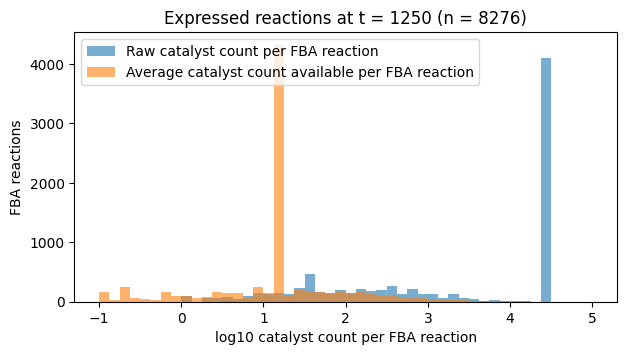

,count,mean,std,min,5%,25%,50%,75%,95%,max
raw_count,8276.0,14185.076365,13843.353085,1.000000,7.0,83.000000,7301.000000,28119.0,28119.00,45373.0
avg_cat_count_per_rxn,8276.0,113.297250,912.770683,0.030303,0.2,13.716585,13.716585,15.0,366.75,45373.0


In [30]:
expressed = rxn_df[rxn_df["status"] == "expressed"]
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(-1, 5, 49)
ax.hist(np.log10(expressed["raw_count"]), bins=bins, alpha=0.6, label="Raw catalyst count per FBA reaction")
ax.hist(np.log10(expressed["avg_cat_count_per_rxn"].clip(lower=1e-1)), bins=bins, alpha=0.6, label="Average catalyst count available per FBA reaction")
ax.set_xlabel("log10 catalyst count per FBA reaction")
ax.set_ylabel("FBA reactions")
ax.set_title(f"Expressed reactions at t = {T} (n = {len(expressed)})")
ax.legend()
display(fig)
plt.close(fig)
expressed[["raw_count", "avg_cat_count_per_rxn"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T

## 3. FBA inputs for the snapshot

Same conversions as `MetabolismReduxClassic.next_update`. The listeners store counts; the solver works in concentration per step:
```
concentration = count × c2m / Δt     (fluxes, dm/dt targets, maintenance)
concentration = count × c2m          (homeostatic metabolite levels)
```
Listener counts are rounded to whole molecules, so the rebuild is close to, not identical to, the sim's solve.

In [33]:
homeostatic_concs = np.asarray(fba["homeostatic_metabolite_counts"][T], dtype=float) * c2m
homeostatic_dm_targets = np.asarray(fba["target_homeostatic_dmdt"][T], dtype=float) * c2m / dt
kinetic_targets = np.asarray(fba["target_kinetic_fluxes"][T], dtype=float) * c2m / dt
maintenance_target = float(fba["maintenance_target"][T]) * c2m / dt
binary_kinetic_idx = np.asarray(fba["binary_kinetic_idx"][T], dtype=int)  # enzyme absent -> flux 0

model = NetworkFlowModel(
    stoich_arr=metabolism.stoichiometry,
    metabolites=list(metabolism.metabolite_names),
    reactions=reaction_names,
    homeostatic_metabolites=list(metabolism.homeostatic_metabolites),
    kinetic_reactions=list(metabolism.kinetic_constraint_reactions),
)
model.set_up_exchanges(exchanges=set(metabolism.exchange_molecules),
                       uptakes=set(metabolism.allowed_exchange_uptake))
print(f"{model.n_orig_rxns} reactions, {model.n_exch_rxns} exchange columns, "
      f"{len(binary_kinetic_idx)} reactions forced to 0, maintenance = {maintenance_target:.3e}")

9456 reactions, 86 exchange columns, 100 reactions forced to 0, maintenance = 3.118e+00


## 4. The FBA problem in CVXPY

Mirrors `NetworkFlowModel.solve`. A diversity term is a function `v -> (expression, extra_constraints)`.

In [43]:
UPPER_FLUX_BOUND = 100


def solve_snapshot(diversity_fn=None, weights=None, solver=cp.GLOP):
    w = {**sim_weights, **(weights or {})}
    v = cp.Variable(model.n_orig_rxns)
    e = cp.Variable(model.n_exch_rxns)
    dm = model.S_orig @ v + model.S_exch @ e

    constr = [dm[model.intermediates_idx] == 0,
              v >= 0, v <= UPPER_FLUX_BOUND, e >= 0, e <= UPPER_FLUX_BOUND]
    if model.maintenance_idx is not None:
        constr.append(v[model.maintenance_idx] == maintenance_target)
    if len(binary_kinetic_idx):
        constr.append(v[binary_kinetic_idx] == 0)

    terms = {
        "homeostatic": cp.norm1((dm[model.homeostatic_idx] - homeostatic_dm_targets) / homeostatic_concs),
        "secretion": cp.sum(e[model.secretion_idx]),
        "efficiency": cp.sum(v),
        "kinetics": cp.norm1(v[model.kinetic_rxn_idx] - kinetic_targets * fraction_kinetic_target),
    }
    if diversity_fn is not None:
        expr, extra = diversity_fn(v)
        terms["diversity"] = expr
        constr += extra

    loss = sum(w[k] * t for k, t in terms.items() if w.get(k, 0))
    problem = cp.Problem(cp.Minimize(loss), constr)
    t0 = time.perf_counter()
    problem.solve(solver=solver)
    elapsed = time.perf_counter() - t0
    if problem.status != "optimal":
        raise ValueError(f"solve status: {problem.status}")
    return {
        "v": np.asarray(v.value),
        "objective": problem.value,
        "terms": {k: float(t.value) for k, t in terms.items()},
        "solve_s": elapsed,
    }


# Candidate diversity terms --------------------------------------------------
def mad_term(v):
    mean_flux = cp.Variable()
    return cp.sum(cp.abs(v - mean_flux)), [mean_flux == cp.sum(v) / v.shape[0]]


def floor_term(eps_pair):
    # Σ (1/ε_r) max(0, ε_r - g_r) over pairs with ε_r > 0
    idx = np.flatnonzero(eps_pair > 0)
    def build(v):
        g = (G @ v)[idx]
        return cp.sum(cp.multiply(1.0 / eps_pair[idx], cp.pos(eps_pair[idx] - g))), []
    return build


def pair_floor(eps_rxn):
    # ε_r = max over the pair's FBA reactions
    eps_pair = np.zeros(n_pairs)
    np.maximum.at(eps_pair, pair_of_rxn, eps_rxn)
    return eps_pair


def enzyme_floor_eps(k_cat_min, eps_hi=1.0, include_uncatalyzed=False):
    # ε_i = clip(k_cat_min × Δt × avg_cat_count_per_rxn_i × c2m, c2m, eps_hi) for expressed reactions
    eps = np.where(rxn_catalyst_counts > 0,
                   np.clip(k_cat_min * dt * avg_cat_count_per_rxn * c2m, c2m, eps_hi), 0.0)
    if include_uncatalyzed:
        eps = np.where(rxn_catalyst_counts < 0, c2m, eps)
    return pair_floor(eps)


uniform_eps_pair = pair_floor(np.full(len(reaction_names), c2m))

## 5. Check the rebuild against the sim

Re-solve with the sim's own term (MAD) and weights, then compare with the fluxes the sim logged at this step.

In [44]:
### Enzymatic Floor TERM ###
check = solve_snapshot(mad_term)
v_sim = np.asarray(fba["solution_fluxes"][T], dtype=float)
diff = np.abs(check["v"] - v_sim)
print(f"solve {check['solve_s']:.2f} s")
print(f"homeostatic term: rebuild {check['terms']['homeostatic']:.4g} vs sim {fba['homeostatic_term'][T]:.4g}")
print(f"flux agreement: max |diff| = {diff.max():.3e}, "
      f"reactions within 1 molecule/step: {np.mean(diff <= c2m):.1%}, "
      f"Pearson r = {np.corrcoef(check['v'], v_sim)[0, 1]:.4f}")

solve 1.50 s
homeostatic term: rebuild 4.29e-13 vs sim 1.568e-12
flux agreement: max |diff| = 5.473e-01, reactions within 1 molecule/step: 97.4%, Pearson r = 0.9958


## 6. Compare diversity terms

Metrics per candidate:
- **pairs carrying flux**: g_r ≥ 1 molecule per step (all pairs)
- **expressed pairs ≥ 1 molecule**: same, restricted to pairs with an expressed catalyst
- **expressed pairs ≥ enzyme floor (k_cat_min = 0.1)**: one fixed yardstick for every candidate
- **Spearman(flux, enzyme)**: across expressed pairs, flux vs capacity-shared catalyst count (higher = flux tracks expression)

Note: the snapshot inputs come from whichever sim you load. With the MAD run, the cell's homeostatic deficits reflect MAD's history, so even "no diversity term" has a homeostatic term above zero here.

In [54]:
pair_enzyme = np.zeros(n_pairs)
np.maximum.at(pair_enzyme, pair_of_rxn, np.where(rxn_catalyst_counts > 0, avg_cat_count_per_rxn, 0.0))
expressed_pairs = pair_enzyme > 0


# Fixed yardstick for every candidate: the k_cat_min = 0.1 enzyme floor
EPS_YARDSTICK = enzyme_floor_eps(k_cat_min=0.1)


def summarize(name, res):
    g = G @ res["v"]
    tol = 1 - 1e-6
    rho = spearmanr(g[expressed_pairs], pair_enzyme[expressed_pairs]).statistic
    return {
        "candidate": name,
        "solve_s": round(res["solve_s"], 2),
        "homeostatic": res["terms"]["homeostatic"],
        "pairs_carrying_flux": int(np.sum(g >= c2m * tol)),
        "expressed_pairs_>=1_molecule": int(np.sum((g >= c2m * tol) & expressed_pairs)),
        "expressed_pairs_>=enzyme_floor(k_cat_min=0.1)": int(np.sum((g >= EPS_YARDSTICK * tol) & expressed_pairs)),
        "spearman_flux_vs_enzyme": round(rho, 3),
    }


candidates = {
    "no diversity term": (None, {"diversity": 0}),
    "uniform floor, λ=1e-4": (floor_term(uniform_eps_pair), {"diversity": 1e-4}),
}
for k_cat_min in [0.1, 1.0, 2.0]:
    candidates[f"enzyme floor k_cat_min={k_cat_min}, λ=1e-4"] = (floor_term(enzyme_floor_eps(k_cat_min)), {"diversity": 1e-4})

results, rows = {}, []
for name, (fn, w) in candidates.items():
    results[name] = solve_snapshot(fn, w)
    rows.append(summarize(name, results[name]))
print(f"{expressed_pairs.sum()} of {n_pairs} pairs have an expressed catalyst")
pd.DataFrame(rows).set_index("candidate")

/Users/heenasaqib/dev/vEcoli/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


5849 of 6795 pairs have an expressed catalyst


,solve_s,homeostatic,pairs_carrying_flux,expressed_pairs_>=1_molecule,expressed_pairs_>=enzyme_floor(k_cat_min=0.1),spearman_flux_vs_enzyme
candidate,,,,,,
no diversity term,0.12,3.763376e-13,440,408,379,0.315
"uniform floor, λ=1e-4",0.23,6.194645e-12,4241,3839,937,0.268
"enzyme floor k_cat_min=0.1, λ=1e-4",0.21,2.024615e-04,3960,3839,3823,0.454
"enzyme floor k_cat_min=1.0, λ=1e-4",0.21,9.226029e-13,3954,3832,3811,0.453
"enzyme floor k_cat_min=2.0, λ=1e-4",0.22,2.789867e-04,3955,3830,3810,0.443


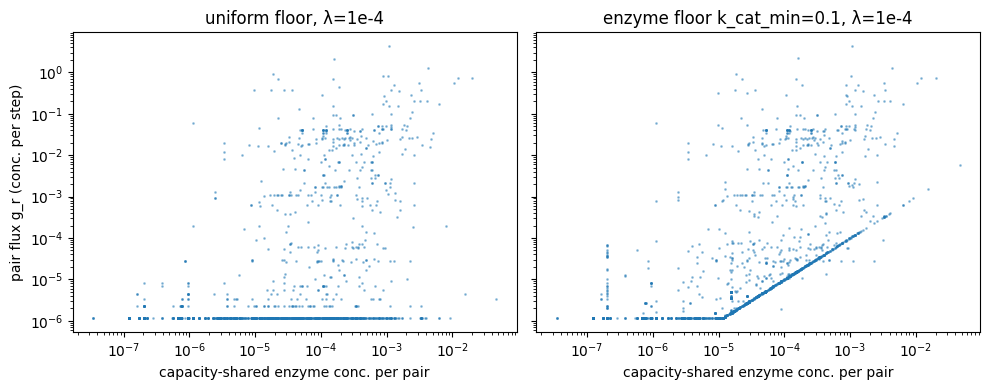

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, name in zip(axes, ["uniform floor, λ=1e-4", "enzyme floor k_cat_min=0.1, λ=1e-4"]):
    g = G @ results[name]["v"]
    m = expressed_pairs & (g > 1e-12)  # drop solver round-off
    ax.loglog(pair_enzyme[m] * c2m, g[m], ".", ms=2, alpha=0.4)
    ax.set_title(name)
    ax.set_xlabel("capacity-shared enzyme conc. per pair")
axes[0].set_ylabel("pair flux g_r (conc. per step)")
plt.tight_layout()
display(fig)
plt.close(fig)

## Next things to try

- Sweep `k_cat_min` (e.g. 0.01–10 s⁻¹) and λ (e.g. 1e-8–1e-3) and watch homeostatic vs `expressed_pairs_at_floor`.
- Use `f × target_kinetic` as the floor for the 416 kinetic reactions (real kcat) and `k_cat_min` elsewhere.
- `include_uncatalyzed=True` vs False (1080 reactions have no annotated catalyst).
- Try other snapshots (`T`), e.g. early vs late in the cell cycle.
- Check central-carbon fluxes against Toya et al. 2010 for the best candidates.

Plot 1: Catalyst Complex Count versus Pair Flux for the imported sim. Scatter plot. Color dots (complexes) that are created by new reactions.

243 of 1562 catalysts are encoded by new genes
averaged over 2500 steps; flux conserved by the split: credited 73100 vs catalyzed 73100


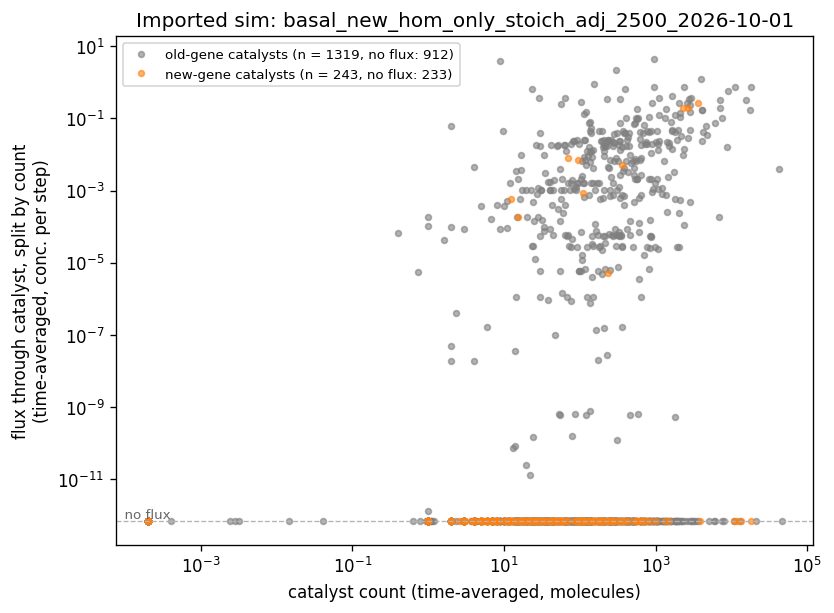

Spearman(count, flux), all catalysts (n = 1521): 0.336
Spearman(count, flux), new-gene catalysts (n = 237): 0.172


In [64]:
# [scout-plot-1] Catalyst count vs total flux through that catalyst (imported sim, time-averaged)
#   pair flux       g_r(t)   = Σ_{j ∈ pair r} v_j(t)
#   share           s_re(t)  = c_e(t) / Σ_{e' ∈ C_r} c_e'(t)        (split by catalyst count)
#   catalyst flux   F_e      = mean_t Σ_r g_r(t) × s_re(t)
#   catalyst count  N_e      = mean_t c_e(t)
import ast
import re


def _parse_enzymes(value):
    # same parsing as _parse_enzyme_list() in 202607_plot_gene_flux_dumbbell.py
    if pd.isna(value):
        return []
    value = str(value).strip()
    return ast.literal_eval(value) if value.startswith("[") else [value]


# "New" catalyst = encoded by a new (2022) gene, per new_metabolic_gene_annotation.csv
genes_df = pd.read_csv(Path.cwd() / "new_metabolic_gene_annotation.csv")
new_enzymes = {e for v in genes_df["Enzyme encoded"] for e in _parse_enzymes(v)}
catalyst_base_ids = [re.sub(r"\[[^\]]*\]$", "", c) for c in catalyst_ids]  # drop [compartment]
is_new_catalyst = np.isin(catalyst_base_ids, list(new_enzymes))
n_cat = len(catalyst_ids)
print(f"{is_new_catalyst.sum()} of {n_cat} catalysts are encoded by new genes")

# Pair x catalyst incidence (a pair's catalysts = union over its forward/reverse reactions)
inc_rows, inc_cols = [], []
for i, enz_idx in enumerate(metabolism.catalyzed_rxn_enzymes_idx):
    for e in enz_idx:
        inc_rows.append(pair_of_rxn[i])
        inc_cols.append(e)
B = csr_matrix((np.ones(len(inc_rows)), (inc_rows, inc_cols)), shape=(n_pairs, n_cat))
B.sum_duplicates()
B.data[:] = 1.0

# Accumulate over every step that has a solve (t = 0 is an empty listener row)
steps = [t for t in range(n_steps) if len(fba["solution_fluxes"][t]) == len(reaction_names)]
credit_sum = np.zeros(n_cat)
count_sum = np.zeros(n_cat)
catalyzed_total = credited_total = 0.0
for t in steps:
    g_t = G @ np.asarray(fba["solution_fluxes"][t], dtype=float)
    c_t = np.asarray(fba["catalyst_counts"][t], dtype=float)
    W = B.multiply(c_t[None, :]).tocsr()           # W[r, e] = c_e(t) if e catalyzes pair r
    row_total = np.asarray(W.sum(axis=1)).ravel()   # Σ_{e' ∈ C_r} c_e'(t)
    has_cat = row_total > 0
    per_count = np.zeros(n_pairs)
    per_count[has_cat] = g_t[has_cat] / row_total[has_cat]
    credit = W.T @ per_count                        # Σ_r g_r × c_e / Σ c
    credit_sum += credit
    count_sum += c_t
    catalyzed_total += g_t[has_cat].sum()
    credited_total += credit.sum()

catalyst_mean_count = count_sum / len(steps)
catalyst_mean_flux = credit_sum / len(steps)
print(f"averaged over {len(steps)} steps; flux conserved by the split: "
      f"credited {credited_total:.6g} vs catalyzed {catalyzed_total:.6g}")

# Log-log scatter; zeros piled on the axis edges
ZERO_FLUX = 1e-12
x_edge = 0.5 * catalyst_mean_count[catalyst_mean_count > 0].min()
y_edge = 0.5 * max(catalyst_mean_flux[catalyst_mean_flux > ZERO_FLUX].min(), ZERO_FLUX)
no_count = catalyst_mean_count <= 0
no_flux = catalyst_mean_flux <= ZERO_FLUX
x_plot = np.where(no_count, x_edge, catalyst_mean_count)
y_plot = np.where(no_flux, y_edge, catalyst_mean_flux)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for mask, label, color in [(~is_new_catalyst, "old-gene catalysts", "tab:gray"),
                           (is_new_catalyst, "new-gene catalysts", "tab:orange")]:
    ax.loglog(x_plot[mask], y_plot[mask], "o", ms=3.5, alpha=0.6, color=color,
              label=f"{label} (n = {mask.sum()}, no flux: {np.sum(no_flux & mask)})")
ax.axhline(y_edge, color="0.7", lw=0.8, ls="--")
ax.text(ax.get_xlim()[0], y_edge, "  no flux", va="bottom", fontsize=8, color="0.4")
ax.set_xlabel("catalyst count (time-averaged, molecules)")
ax.set_ylabel("flux through catalyst, split by count\n(time-averaged, conc. per step)")
ax.set_title(f"Imported sim: {SIM_FOLDER.name}")
ax.legend(loc="upper left", fontsize=8)
display(fig)


has_count = ~no_count
for label, mask in [("all catalysts", has_count), ("new-gene catalysts", has_count & is_new_catalyst)]:
    rho = spearmanr(catalyst_mean_count[mask], catalyst_mean_flux[mask]).statistic
    print(f"Spearman(count, flux), {label} (n = {mask.sum()}): {rho:.3f}")
catalyst_flux_df = pd.DataFrame({
    "catalyst": catalyst_ids,
    "new_gene": is_new_catalyst,
    "mean_count": catalyst_mean_count,
    "mean_flux": catalyst_mean_flux,
    "reaction_pairs_served": n_rxn_involved_per_cat,
})

plt.savefig(f'{SIM_FOLDER}/plot/catalyst_count_vs_flux.svg', dpi=300, bbox_inches="tight")
plt.close(fig)

Plot 2: Sweep k_cat_min and lambda_div, report homeostatic term and expressed pairs at floor. Heatmap.

42 solves, 0 not optimal, median solve 0.22 s, 5849 expressed pairs get a floor


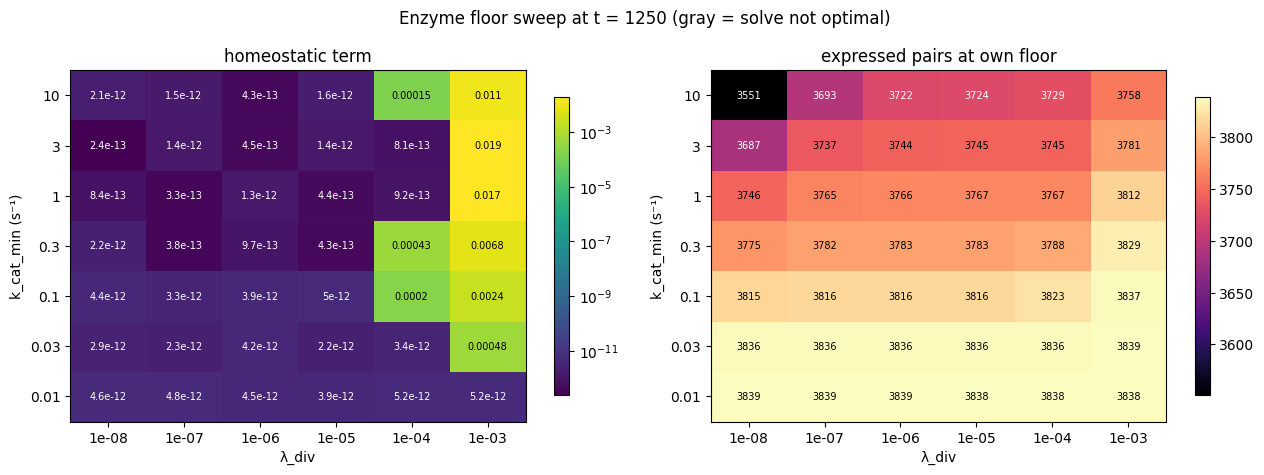

In [68]:
# [scout-plot-2] k_cat_min x λ_div sweep at snapshot T
#   floor   ε_r = enzyme_floor_eps(k_cat_min)        (0 = no floor for that pair)
#   metric  pairs at own floor = Σ_r [ g_r ≥ ε_r  and  pair r expressed  and  ε_r > 0 ]
from matplotlib.colors import LogNorm

K_CAT_MIN_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
LAMBDA_GRID = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]

sweep_rows = []
for k in K_CAT_MIN_GRID:
    eps = enzyme_floor_eps(k)
    floored = expressed_pairs & (eps > 0)
    for lam in LAMBDA_GRID:
        row = {"k_cat_min": k, "lambda_div": lam, "n_floored_pairs": int(floored.sum())}
        try:
            res = solve_snapshot(floor_term(eps), {"diversity": lam})
            g = G @ res["v"]
            row.update(status="optimal", homeostatic=res["terms"]["homeostatic"],
                       pairs_at_own_floor=int(np.sum((g >= eps * (1 - 1e-6)) & floored)),
                       solve_s=res["solve_s"])
        except Exception as err:
            row.update(status=f"{type(err).__name__}: {err}"[:80], homeostatic=np.nan,
                       pairs_at_own_floor=np.nan, solve_s=np.nan)
        sweep_rows.append(row)
sweep_df = pd.DataFrame(sweep_rows)
n_failed = int((sweep_df["status"] != "optimal").sum())
print(f"{len(sweep_df)} solves, {n_failed} not optimal, "
      f"median solve {sweep_df['solve_s'].median():.2f} s, "
      f"{int(sweep_df['n_floored_pairs'].iloc[0])} expressed pairs get a floor")

hom = sweep_df.pivot(index="k_cat_min", columns="lambda_div", values="homeostatic")
at_floor = sweep_df.pivot(index="k_cat_min", columns="lambda_div", values="pairs_at_own_floor")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
panels = [
    (axes[0], hom, "homeostatic term", "viridis",
     LogNorm(vmin=np.nanmin(hom.values[hom.values > 0]), vmax=np.nanmax(hom.values)), "{:.2g}"),
    (axes[1], at_floor, "expressed pairs at own floor", "magma", None, "{:.0f}"),
]
for ax, table, title, cmap_name, norm, fmt in panels:
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("0.8")  # failed solves
    im = ax.imshow(np.ma.masked_invalid(table.values), cmap=cmap, norm=norm, aspect="auto", origin="lower")
    ax.set_xticks(range(len(table.columns)), [f"{c:.0e}" for c in table.columns])
    ax.set_yticks(range(len(table.index)), [f"{k:g}" for k in table.index])
    ax.set_xlabel("λ_div")
    ax.set_ylabel("k_cat_min (s⁻¹)")
    ax.set_title(title)
    for (i, j), val in np.ndenumerate(table.values):
        if np.isfinite(val):
            rgba = im.cmap(im.norm(val))
            text_color = "white" if (0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]) < 0.5 else "black"
            ax.text(j, i, fmt.format(val), ha="center", va="center", fontsize=7, color=text_color)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle(f"Enzyme floor sweep at t = {T} (gray = solve not optimal)")
plt.tight_layout()
display(fig)
plt.savefig(f'/Users/heenasaqib/dev/vEcoli/notebooks/Heena notebooks/Metabolism_New Genes/out/objective_weights/homeostatic_diversity/enzymatic_diversity_param_sweep.svg', dpi=300, bbox_inches="tight", transparent=True)
plt.close(fig)

Plot 3: Do the same "Compare diversity terms" Analysis as above, this time plotting the distribution of fluxes for each candidate diversity term. Histogram distribution. Use transparancy to allow comparison and overlap of distributions. Use log scale for x-axis (fluxes). Use different colors for each candidate diversity term.

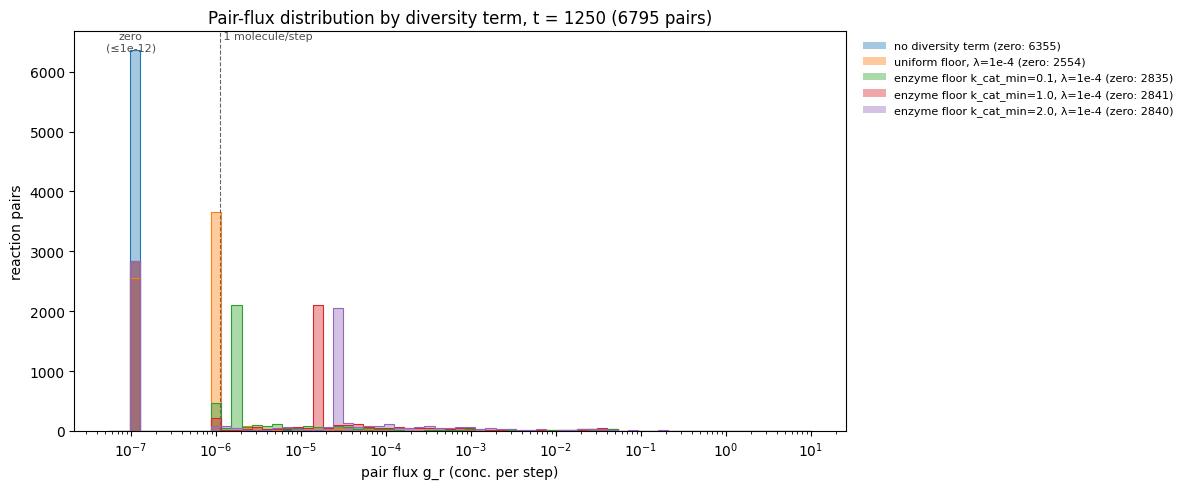

In [70]:
# [scout-plot-3] Pair-flux distributions per candidate diversity term (from `results` above)
#   g_r = Σ_{j ∈ pair r} v_j ;  g_r < 1e-12 (incl. solver round-off) is piled into the left bin
ZERO_FLUX = 1e-7
pair_fluxes = {name: np.maximum(G @ res["v"], ZERO_FLUX) for name, res in results.items()}
log_hi = np.ceil(np.log10(max(f.max() for f in pair_fluxes.values())))
bins = np.logspace(np.log10(ZERO_FLUX) - 0.25, log_hi, 70)  # ZERO_FLUX sits inside the first bin

fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.get_cmap("tab10").colors
for (name, g), color in zip(pair_fluxes.items(), colors):
    n_zero = int(np.sum(g <= ZERO_FLUX))
    ax.hist(g, bins=bins, alpha=0.4, color=color, label=f"{name} (zero: {n_zero})")
    ax.hist(g, bins=bins, histtype="step", color=color, lw=0.8)
ax.set_xscale("log")
ax.axvline(c2m, color="0.4", lw=0.8, ls="--")
ax.text(c2m, ax.get_ylim()[1], " 1 molecule/step", va="top", fontsize=8, color="0.3")
ax.text(ZERO_FLUX, ax.get_ylim()[1], "zero\n(≤1e-12)", va="top", ha="center", fontsize=8, color="0.3")
ax.set_xlabel("pair flux g_r (conc. per step)")
ax.set_ylabel("reaction pairs")
ax.set_title(f"Pair-flux distribution by diversity term, t = {T} ({n_pairs} pairs)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.tight_layout()
display(fig)
plt.close(fig)